# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [19]:
import random


class Card:
    def __init__(self, suit, rank):
        self.suit = suit
        self.rank = rank

    def value(self):
        if self.rank in ['J', 'Q', 'K']:
            return 10
        elif self.rank == 'A':
            return 11
        else:
            return int(self.rank)

    def __repr__(self):
        return self.rank + self.suit


class PlasticCard:
    def __repr__(self):
        return 'PLASTIC'


class Deck:
    suits = ['S', 'H', 'D', 'C']
    ranks = ['2','3','4','5','6','7','8','9','10','J','Q','K','A']

    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.needs_shuffle = False
        self.cards = []
        self._build()

    def _build(self):
        self.cards = []
        for _ in range(self.num_decks):
            for suit in self.suits:
                for rank in self.ranks:
                    self.cards.append(Card(suit, rank))
        self.shuffle()

    def shuffle(self):
        random.shuffle(self.cards)
        start = int(len(self.cards) * 0.75)
        end = len(self.cards) - 1
        if start < end:
            pos = random.randint(start, end)
        else:
            pos = end
        self.cards.insert(pos, PlasticCard())
        self.needs_shuffle = False

    def draw(self):
        if not self.cards:
            self._build()
        card = self.cards.pop()
        if isinstance(card, PlasticCard):
            self.needs_shuffle = True
            return self.draw()
        return card

    def __len__(self):
        return len(self.cards)


d = Deck(num_decks=6)
print("deck size:", len(d))
print("5 cards:", [d.draw() for _ in range(5)])


deck size: 313
5 cards: [3H, 2C, 9D, 8H, 2S]


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook.

UML (text version):

```
Card
  suit, rank
  value()

PlasticCard  -- marker only

Deck
  cards, num_decks, needs_shuffle
  shuffle(), draw()

Hand
  cards
  add_card(), total(), is_bust(), is_blackjack(), reset()

Player  (base class)
  name, chips, hand, bet
  place_bet(), wants_hit(), receive_card(), reset()

DealerPlayer  extends Player
  wants_hit()  -- hits on 16 or less

HumanPlayer  extends Player
  wants_hit()  -- asks user

CardCountingPlayer  extends Player
  threshold
  wants_hit()  -- uses Hi-Lo count

Game
  deck, dealer, players, verbose, seen_cards
```
#pdf stored in the lab6 folder


3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [20]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card): pass
    def total(self): pass
    def is_bust(self): pass
    def is_blackjack(self): pass
    def reset(self): pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount): pass
    def wants_hit(self, seen_cards): pass
    def receive_card(self, card): pass
    def reset(self): pass


class DealerPlayer(Player):
    def wants_hit(self, seen_cards): pass


class HumanPlayer(Player):
    def wants_hit(self, seen_cards): pass


class Game:
    def __init__(self, deck, dealer, players, verbose=True):
        self.deck = deck
        self.dealer = dealer
        self.players = players
        self.verbose = verbose

    def deal_initial_cards(self): pass
    def play_round(self): pass
    def resolve_bets(self): pass
    def play_game(self, rounds=50): pass


print("skeleton done")


skeleton done


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [21]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def total(self):
        total = 0
        aces = 0
        for card in self.cards:
            total = total + card.value()
            if card.rank == 'A':
                aces = aces + 1
        while total > 21 and aces > 0:
            total = total - 10
            aces = aces - 1
        return total

    def is_bust(self):
        return self.total() > 21

    def is_blackjack(self):
        return len(self.cards) == 2 and self.total() == 21

    def reset(self):
        self.cards = []

    def __repr__(self):
        return str(self.cards) + ' = ' + str(self.total())


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount):
        if amount > self.chips:
            amount = self.chips
        self.bet = amount
        self.chips = self.chips - amount

    def wants_hit(self, seen_cards):
        return False

    def receive_card(self, card):
        self.hand.add_card(card)

    def reset(self):
        self.hand.reset()
        self.bet = 0

    def __repr__(self):
        return self.name + ' (chips=' + str(self.chips) + ')'


class DealerPlayer(Player):
    def __init__(self, name="Dealer"):
        super().__init__(name, chips=999999)

    def wants_hit(self, seen_cards):
        return self.hand.total() <= 16


class HumanPlayer(Player):
    def wants_hit(self, seen_cards):
        while True:
            answer = input('Your hand: ' + str(self.hand) + '. Hit? (y/n): ')
            answer = answer.strip().lower()
            if answer == 'y':
                return True
            elif answer == 'n':
                return False


class Game:
    def __init__(self, deck, dealer, players, verbose=True):
        self.deck = deck
        self.dealer = dealer
        self.players = players
        self.verbose = verbose
        self.seen_cards = []

    def log(self, msg):
        if self.verbose:
            print(msg)

    def deal_initial_cards(self):
        for _ in range(2):
            for player in self.players:
                card = self.deck.draw()
                player.receive_card(card)
                self.seen_cards.append(card)
            card = self.deck.draw()
            self.dealer.receive_card(card)
            if len(self.dealer.hand.cards) == 1:
                self.seen_cards.append(card)

    def play_round(self, bet_amount=10):
        self.dealer.reset()
        for player in self.players:
            player.reset()

        for player in self.players:
            if player.chips >= bet_amount:
                player.place_bet(bet_amount)

        self.deal_initial_cards()
        self.log("Dealer shows: " + str(self.dealer.hand.cards[0]))

        for player in self.players:
            self.log(player.name + " hand: " + str(player.hand))
            while not player.hand.is_bust() and player.wants_hit(self.seen_cards):
                card = self.deck.draw()
                player.receive_card(card)
                self.seen_cards.append(card)
                self.log("  " + player.name + " hits, gets " + str(card) + ", total: " + str(player.hand.total()))
            if player.hand.is_bust():
                self.log("  " + player.name + " busts!")

        self.log("Dealer full hand: " + str(self.dealer.hand))
        if len(self.dealer.hand.cards) > 1:
            self.seen_cards.append(self.dealer.hand.cards[1])
        while self.dealer.wants_hit(self.seen_cards):
            card = self.deck.draw()
            self.dealer.receive_card(card)
            self.seen_cards.append(card)
            self.log("  Dealer hits, gets " + str(card) + ", total: " + str(self.dealer.hand.total()))

        self.resolve_bets()

        if self.deck.needs_shuffle:
            self.log("--- reshuffling ---")
            self.deck.shuffle()
            self.seen_cards = []

    def resolve_bets(self):
        dealer_total = self.dealer.hand.total()
        dealer_bust = self.dealer.hand.is_bust()

        for player in self.players:
            if player.bet == 0:
                continue
            pt = player.hand.total()
            if player.hand.is_bust():
                result = "busts"
            elif dealer_bust or pt > dealer_total:
                result = "wins"
                player.chips = player.chips + player.bet * 2
            elif pt == dealer_total:
                result = "push"
                player.chips = player.chips + player.bet
            else:
                result = "loses"
            self.log("  " + player.name + ": " + str(pt) + " vs dealer " + str(dealer_total) + " -> " + result)

    def play_game(self, rounds=50, bet_amount=10):
        for _ in range(rounds):
            all_broke = True
            for player in self.players:
                if player.chips >= bet_amount:
                    all_broke = False
            if all_broke:
                break
            self.play_round(bet_amount=bet_amount)


print("implementation done")


implementation done


5. Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [22]:
deck = Deck(num_decks=6)
dealer = DealerPlayer()

players = [
    DealerPlayer("Alice"),
    DealerPlayer("Bob"),
    DealerPlayer("Charlie"),
]
for p in players:
    p.chips = 100

game = Game(deck, dealer, players, verbose=True)

for i in range(3):
    print("\n--- Round", i + 1, "---")
    game.play_round(bet_amount=10)
    for p in players:
        print(" ", p.name, "chips:", p.chips)



--- Round 1 ---
Dealer shows: KD
Alice hand: [3C, 2D] = 5
  Alice hits, gets 7S, total: 12
  Alice hits, gets 6D, total: 18
Bob hand: [2C, QD] = 12
  Bob hits, gets 5D, total: 17
Charlie hand: [6S, JS] = 16
  Charlie hits, gets AC, total: 17
Dealer full hand: [KD, 8S] = 18
  Alice: 18 vs dealer 18 -> push
  Bob: 17 vs dealer 18 -> loses
  Charlie: 17 vs dealer 18 -> loses
  Alice chips: 100
  Bob chips: 90
  Charlie chips: 90

--- Round 2 ---
Dealer shows: 3H
Alice hand: [6S, JH] = 16
  Alice hits, gets 4S, total: 20
Bob hand: [7S, 7D] = 14
  Bob hits, gets 4D, total: 18
Charlie hand: [3C, 9S] = 12
  Charlie hits, gets JD, total: 22
  Charlie busts!
Dealer full hand: [3H, 2H] = 5
  Dealer hits, gets 6D, total: 11
  Dealer hits, gets 6C, total: 17
  Alice: 20 vs dealer 17 -> wins
  Bob: 18 vs dealer 17 -> wins
  Charlie: 22 vs dealer 17 -> busts
  Alice chips: 110
  Bob chips: 100
  Charlie chips: 80

--- Round 3 ---
Dealer shows: 4D
Alice hand: [5D, 9D] = 14
  Alice hits, gets 6H, tot

6. Implement a new player with the following strategy:

* Assign each card a value:
    * Cards 2 to 6 are +1
    * Cards 7 to 9 are 0
    * Cards 10 through Ace are -1
* Compute the sum of the values for all cards seen so far.
* Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.

In [23]:
class CardCountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def card_value(self, card):
        if card.rank in ['2','3','4','5','6']:
            return 1
        elif card.rank in ['7','8','9']:
            return 0
        else:
            return -1

    def running_count(self, seen_cards):
        count = 0
        for card in seen_cards:
            count = count + self.card_value(card)
        return count

    def wants_hit(self, seen_cards):
        my_total = self.hand.total()
        if my_total >= 17:
            return False
        if my_total <= 11:
            return True
        count = self.running_count(seen_cards)
        return count < self.threshold


c = CardCountingPlayer("Counter", chips=100, threshold=0)
print(c)


Counter (chips=100)


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings.

In [24]:
def run_one_game(threshold=0, rounds=50, starting_chips=100, bet=10, verbose=False):
    deck = Deck(num_decks=6)
    dealer = DealerPlayer()

    counter = CardCountingPlayer("Counter", chips=starting_chips, threshold=threshold)

    other_players = []
    for i in range(3):
        p = DealerPlayer("Player" + str(i + 1))
        p.chips = starting_chips
        other_players.append(p)

    all_players = other_players + [counter]
    game = Game(deck, dealer, all_players, verbose=verbose)
    game.play_game(rounds=rounds, bet_amount=bet)

    return counter.chips


result = run_one_game(threshold=0, rounds=50, starting_chips=100, bet=10, verbose=True)
print("\nCounter ended with:", result, "chips (started with 100)")
print("Net:", result - 100)


Dealer shows: 7S
Player1 hand: [5S, 3D] = 8
  Player1 hits, gets 2C, total: 10
  Player1 hits, gets JC, total: 20
Player2 hand: [QH, 9H] = 19
Player3 hand: [3D, 3C] = 6
  Player3 hits, gets AC, total: 17
Counter hand: [6C, 7H] = 13
Dealer full hand: [7S, 10H] = 17
  Player1: 20 vs dealer 17 -> wins
  Player2: 19 vs dealer 17 -> wins
  Player3: 17 vs dealer 17 -> push
  Counter: 13 vs dealer 17 -> loses
Dealer shows: 4H
Player1 hand: [KD, AS] = 21
Player2 hand: [7D, QH] = 17
Player3 hand: [AH, 3H] = 14
  Player3 hits, gets 9D, total: 13
  Player3 hits, gets QC, total: 23
  Player3 busts!
Counter hand: [9D, 9S] = 18
Dealer full hand: [4H, JD] = 14
  Dealer hits, gets JC, total: 24
  Player1: 21 vs dealer 24 -> wins
  Player2: 17 vs dealer 24 -> wins
  Player3: 23 vs dealer 24 -> busts
  Counter: 18 vs dealer 24 -> wins
Dealer shows: 8S
Player1 hand: [8C, 6C] = 14
  Player1 hits, gets 5D, total: 19
Player2 hand: [3S, 4C] = 7
  Player2 hits, gets KH, total: 17
Player3 hand: [5H, 8H] = 13
 

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?

average chips after 50 rounds: 69.6
std deviation: 63.26
avg winnings per round: -0.608
prob of net win: 0.27
prob of net loss: 0.67


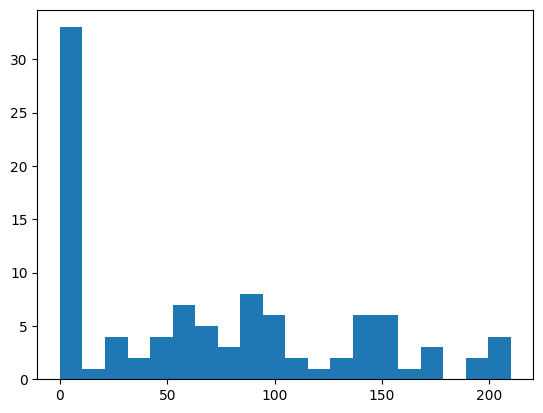

In [25]:
winnings = []
for _ in range(100):
    final = run_one_game(threshold=0, rounds=50, starting_chips=100, bet=10)
    winnings.append(final)

total = 0
for w in winnings:
    total = total + w
avg = total / len(winnings)

variance = 0
for w in winnings:
    variance = variance + (w - avg) ** 2
std = (variance / len(winnings)) ** 0.5

wins = 0
losses = 0
for w in winnings:
    if w > 100:
        wins = wins + 1
    elif w < 100:
        losses = losses + 1

print("average chips after 50 rounds:", round(avg, 2))
print("std deviation:", round(std, 2))
print("avg winnings per round:", round((avg - 100) / 50, 4))
print("prob of net win:", round(wins / len(winnings), 2))
print("prob of net loss:", round(losses / len(winnings), 2))

import matplotlib.pyplot as plt
plt.hist(winnings, bins=20)
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [26]:
thresholds = [-4, -2, 0, 2, 4, 6]
results = {}

for t in thresholds:
    wins_list = []
    for _ in range(100):
        wins_list.append(run_one_game(threshold=t, rounds=50, starting_chips=100, bet=10))
    results[t] = wins_list

print("threshold   avg_chips   prob_win")
for t in thresholds:
    w = results[t]
    total = 0
    for x in w:
        total = total + x
    avg = total / len(w)
    wins = 0
    for x in w:
        if x > 100:
            wins = wins + 1
    print(t, "   ", round(avg, 1), "   ", round(wins / len(w), 2))

best_t = thresholds[0]
best_avg = 0
for t in thresholds:
    total = 0
    for x in results[t]:
        total = total + x
    avg = total / len(results[t])
    if avg > best_avg:
        best_avg = avg
        best_t = t
print("best threshold:", best_t, "with avg chips:", round(best_avg, 2))


threshold   avg_chips   prob_win
-4     57.7     0.2
-2     54.7     0.17
0     65.3     0.27
2     62.5     0.24
4     66.9     0.22
6     54.3     0.19
best threshold: 4 with avg chips: 66.9


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings.

In [27]:
# Basic strategy: stand on 12-16 when count is negative (deck is high-card heavy)

class BasicStrategyPlayer(Player):
    def running_count(self, seen_cards):
        count = 0
        for card in seen_cards:
            if card.rank in ['2','3','4','5','6']:
                count = count + 1
            elif card.rank in ['10','J','Q','K','A']:
                count = count - 1
        return count

    def wants_hit(self, seen_cards):
        my_total = self.hand.total()
        if my_total <= 11:
            return True
        if my_total >= 17:
            return False
        count = self.running_count(seen_cards)
        return count >= 0


def run_basic_game(rounds=50, starting_chips=100, bet=10):
    deck = Deck(num_decks=6)
    dealer = DealerPlayer()
    sp = BasicStrategyPlayer("Basic", chips=starting_chips)
    other_players = []
    for i in range(3):
        p = DealerPlayer("Player" + str(i + 1))
        p.chips = starting_chips
        other_players.append(p)
    game = Game(deck, dealer, other_players + [sp], verbose=False)
    game.play_game(rounds=rounds, bet_amount=bet)
    return sp.chips


basic_wins = []
for _ in range(100):
    basic_wins.append(run_basic_game())

total_b = 0
for w in basic_wins:
    total_b = total_b + w
avg_basic = total_b / len(basic_wins)

total_h = 0
for w in results[0]:
    total_h = total_h + w
avg_hilo = total_h / len(results[0])

print("Hi-Lo counter (threshold=0):", round(avg_hilo, 2))
print("Basic strategy:             ", round(avg_basic, 2))


Hi-Lo counter (threshold=0): 65.3
Basic strategy:              55.4
